# Install Requirements

In [ ]:
!pip install numpy pandas scikit-learn torch

In [ ]:
!pip install torch-geometric

# Start Coding for CMaps dataset

In [ ]:
# =======================
# 0) Imports & Repro
# =======================
# import required libraries
import pandas as pd
import numpy as np
import sklearn
from sklearn import metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
import keras
# import keras.backend as K
from tensorflow.keras import backend as K
from keras.layers import Dense , LSTM, Dropout, Activation
from keras.models import Sequential, load_model
import seaborn as sns
import matplotlib.pyplot as plt
from pylab import rcParams
import math
import xgboost
import time
from tqdm import tqdm
import pickle
from tensorflow.keras.models import save_model, load_model


## Connect to Drive

In [ ]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = '/content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/'



fd_001_train = pd.read_csv(base_path + "train_FD001.txt", sep='\s+', header=None)
fd_001_test = pd.read_csv(base_path + "test_FD001.txt", sep='\s+', header=None)

fd_001_train


<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-558660188.py:5: SyntaxWarning: invalid escape sequence '\s'
  fd_001_train = pd.read_csv(base_path + "train_FD001.txt", sep='\s+', header=None)
/tmp/ipython-input-558660188.py:6: SyntaxWarning: invalid escape sequence '\s'
  fd_001_test = pd.read_csv(base_path + "test_FD001.txt", sep='\s+', header=None)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [ ]:
base_model_path = base_path + "Models/LSTM/"

In [ ]:
fd_001_train.describe()


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.737553,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [ ]:
columns = ['unit_number','time_in_cycles','setting_1','setting_2','TRA','T2','T24','T30','T50','P2','P15','P30','Nf',
           'Nc','epr','Ps30','phi','NRf','NRc','BPR','farB','htBleed','Nf_dmd','PCNfR_dmd','W31','W32' ]

In [ ]:
fd_001_train.columns = columns
fd_001_test.columns = columns

In [ ]:
#initial acquaintance with data
fd_001_train.describe()

,unit_number,time_in_cycles,setting_1,setting_2,TRA,T2,T24,T30,T50,P2,...,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.737553,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [ ]:
#delete columns with constant values ​​that do not carry information about the state of the unit
fd_001_train.drop(columns=['Nf_dmd','PCNfR_dmd','P2','T2','TRA','farB','epr'],inplace=True)

In [ ]:
#function for preparing training data and forming a RUL column with information about the remaining
# before breaking cycles
def prepare_train_data(data, factor = 0):
    df = data.copy()
    fd_RUL = df.groupby('unit_number')['time_in_cycles'].max().reset_index()
    fd_RUL = pd.DataFrame(fd_RUL)
    fd_RUL.columns = ['unit_number','max']
    df = df.merge(fd_RUL, on=['unit_number'], how='left')
    df['RUL'] = df['max'] - df['time_in_cycles']
    df.drop(columns=['max'],inplace = True)

    return df[df['time_in_cycles'] > factor]

In [ ]:
df = prepare_train_data(fd_001_train)

In [ ]:
df

,unit_number,time_in_cycles,setting_1,setting_2,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,NRc,BPR,htBleed,W31,W32,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,643.49,1597.98,1428.63,21.61,551.43,2388.19,9065.52,48.07,519.49,2388.26,8137.60,8.4956,397,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,643.54,1604.50,1433.58,21.61,550.86,2388.23,9065.11,48.04,519.68,2388.22,8136.50,8.5139,395,38.30,23.1594,3
20628,100,198,0.0004,0.0000,643.42,1602.46,1428.18,21.61,550.94,2388.24,9065.90,48.09,520.01,2388.24,8141.05,8.5646,398,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,643.23,1605.26,1426.53,21.61,550.68,2388.25,9073.72,48.39,519.67,2388.23,8139.29,8.5389,395,38.29,23.0640,1


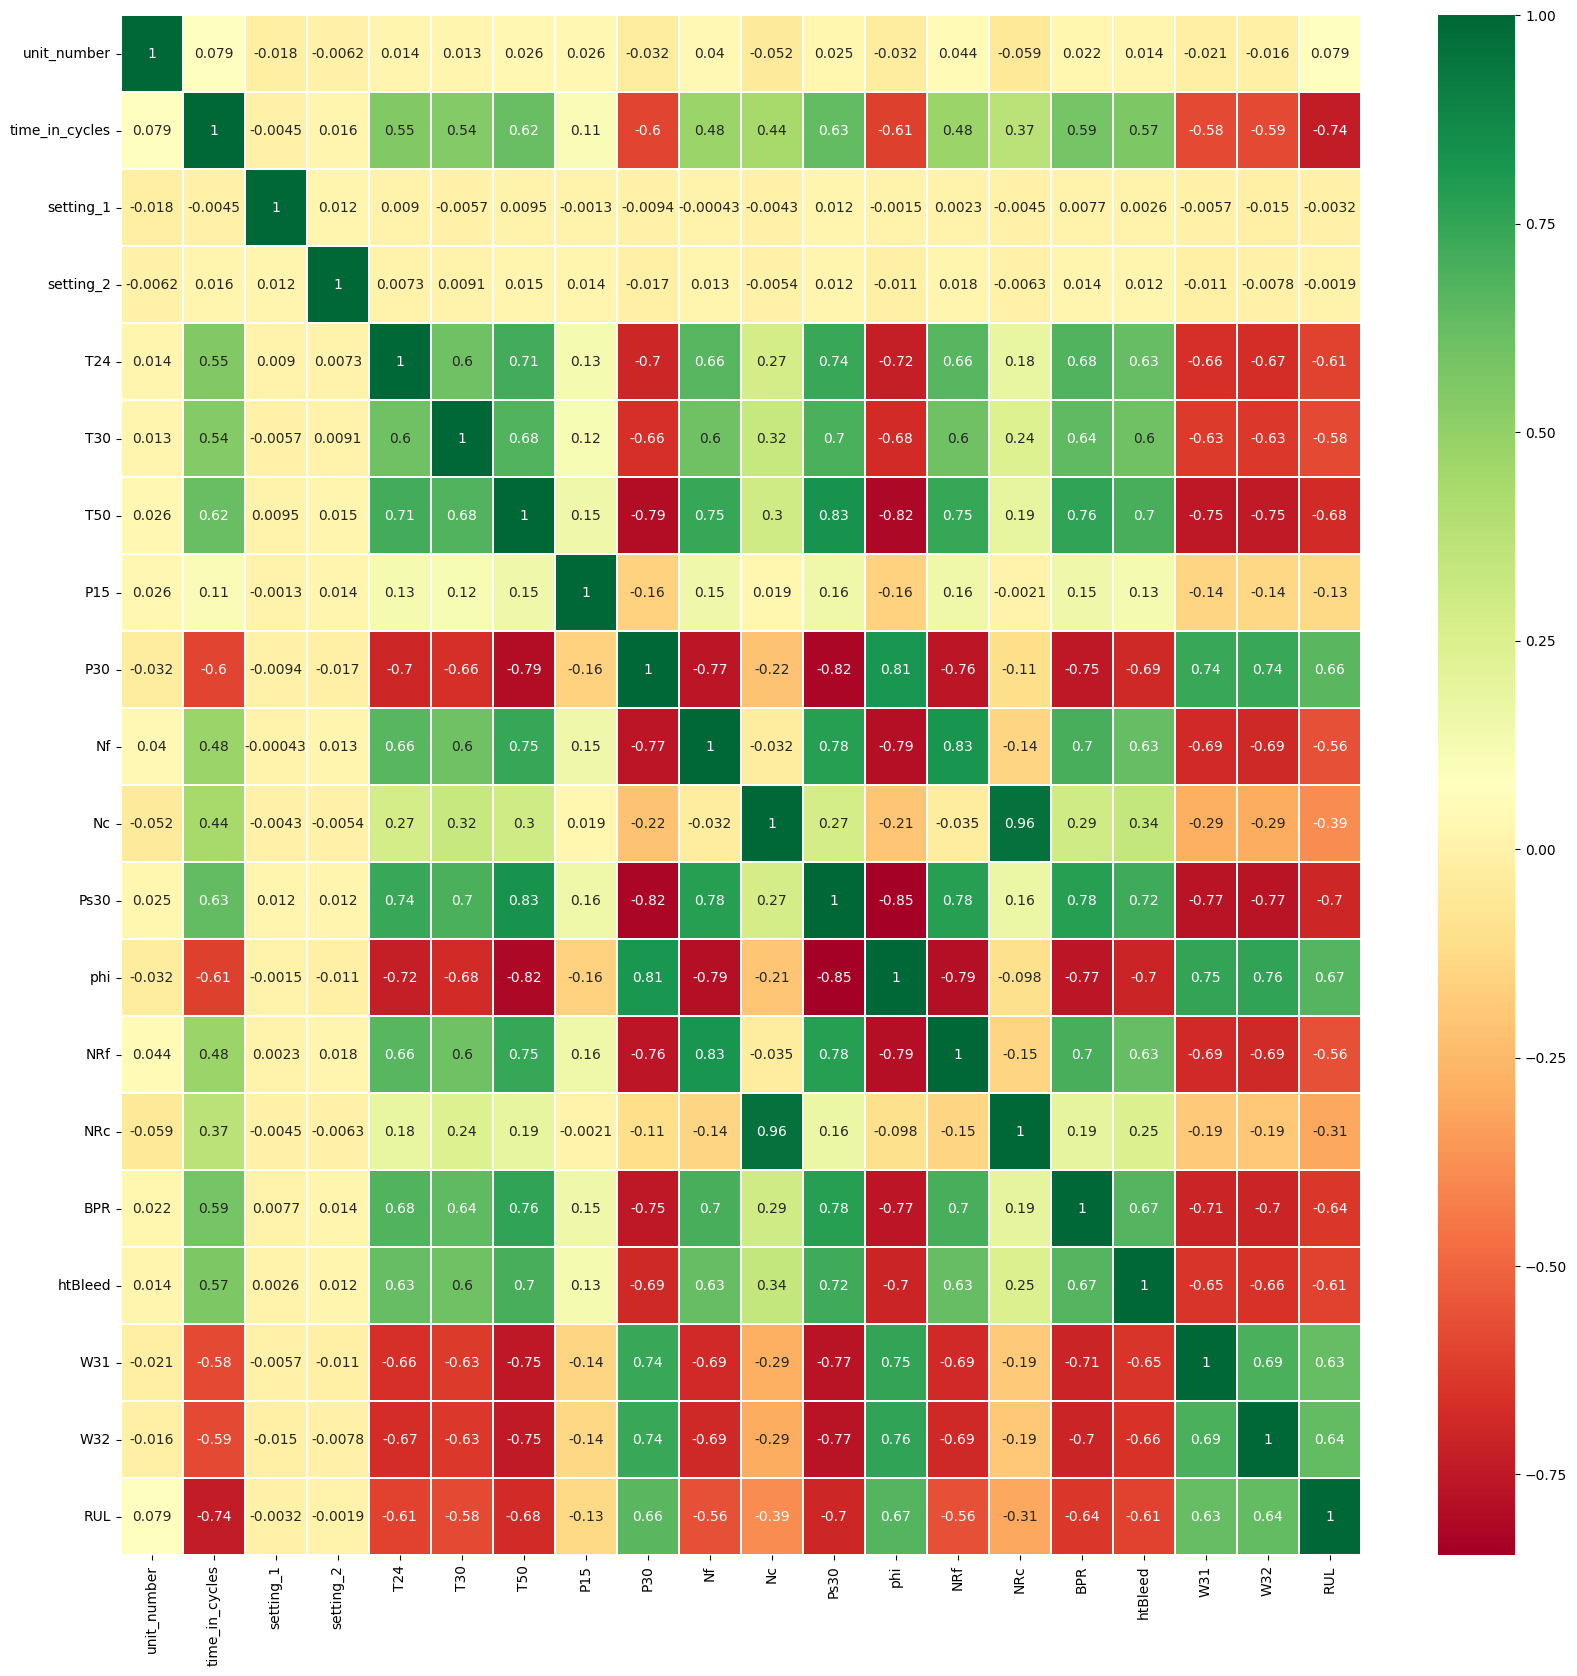

In [ ]:
sns.heatmap(df.corr(),annot=True,cmap='RdYlGn',linewidths=0.2)
fig=plt.gcf()
fig.set_size_inches(20,20)
plt.show()

In [ ]:
#Error Function for Competitive Data
def score(y_true,y_pred,a1=10,a2=13):
    score = 0
    d = y_pred - y_true
    for i in d:
        if i >= 0 :
            score += math.exp(i/a2) - 1
        else:
            score += math.exp(- i/a1) - 1
    return score


In [ ]:
def score_func(y_true,y_pred):
    lst = [round(score(y_true,y_pred),2),
          round(mean_absolute_error(y_true,y_pred),2),
          round(mean_squared_error(y_true,y_pred),2)**0.5,
          round(r2_score(y_true,y_pred),2)]

    print(f' compatitive score {lst[0]}')
    print(f' mean absolute error {lst[1]}')
    print(f' root mean squared error {lst[2]}')
    print(f' R2 score {lst[3]}')
    return [lst[1], round(lst[2],2), lst[3]*100]


#### We remove the properties that weakly correlate with the RUL target: setting_1, setting_2, P15, unit_number, as well as one of the features that are highly correlated with each other (Nc and NRc have a correlation coefficient of 0.96, remove NRc)

In [ ]:
unit_number = pd.DataFrame(df["unit_number"])
train_df = df.drop(columns = ['unit_number','setting_1','setting_2','P15','NRc'])

In [ ]:
train_df.head()

,time_in_cycles,T24,T30,T50,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32,RUL
0,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8.4195,392,39.06,23.4190,191
1,2,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8.4318,392,39.00,23.4236,190
2,3,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8.4178,390,38.95,23.3442,189
3,4,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8.3682,392,38.88,23.3739,188
4,5,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8.4294,393,38.90,23.4044,187


## Implementing LSTM

In [ ]:
def lstm_data_preprocessing(raw_train_data, raw_test_data, raw_RUL_data):
    train_df = raw_train_data
    truth_df = raw_RUL_data
    # Removed the line below as RUL_FD001.txt only has one column.
    # truth_df.drop(truth_df.columns[[1]], axis=1, inplace=True)

    #################
    # TRAIN
    #################

    # we will only make use of "label1" for binary classification,
    # while trying to answer the question: is a specific engine going to fail within w1 cycles?
    w1 = 30
    w0 = 15
    train_df['label1'] = np.where(train_df['RUL'] <= w1, 1, 0 )
    train_df['label2'] = train_df['label1']
    train_df.loc[train_df['RUL'] <= w0, 'label2'] = 2

    # MinMax normalization (from 0 to 1)
    train_df['cycle_norm'] = train_df['time_in_cycles']
    cols_normalize = train_df.columns.difference(['unit_number','time_in_cycles','RUL','label1','label2']) # NORMALIZE COLUMNS except [id , cycle, rul ....]

    min_max_scaler = MinMaxScaler()

    norm_train_df = pd.DataFrame(min_max_scaler.fit_transform(train_df[cols_normalize]),
                                 columns=cols_normalize,
                                 index=train_df.index)

    join_df = train_df[train_df.columns.difference(cols_normalize)].join(norm_train_df)
    train_df = join_df.reindex(columns = train_df.columns)
    print("train_df >> ",train_df.head())
    print("\n")


    #################
    # TEST
    #################

#     raw_test_data.drop(columns=['Nf_dmd','PCNfR_dmd','P2','T2','TRA','farB','epr'],inplace=True)
    test_df = raw_test_data.drop(columns = ['setting_1','setting_2','P15','NRc','max'])

    # MinMax normalization (from 0 to 1)
    test_df['cycle_norm'] = test_df['time_in_cycles']
    norm_test_df = pd.DataFrame(min_max_scaler.transform(test_df[cols_normalize]),
                                columns=cols_normalize,
                                index=test_df.index)
    test_join_df = test_df[test_df.columns.difference(cols_normalize)].join(norm_test_df)
    test_df = test_join_df.reindex(columns = test_df.columns)
    test_df = test_df.reset_index(drop=True)

    # We use the ground truth dataset to generate labels for the test data.
    # generate column max for test data
    rul = pd.DataFrame(test_df.groupby('unit_number')['time_in_cycles'].max()).reset_index()
    rul.columns = ['unit_number','max']
    truth_df.columns = ['more']
    truth_df['unit_number'] = truth_df.index + 1
    truth_df['max'] = rul['max'] + truth_df['more'] # adding true-rul vlaue + max cycle of test data set w.r.t MID
    truth_df.drop('more', axis=1, inplace=True)

    # generate RUL for test data
    test_df = test_df.merge(truth_df, on=['unit_number'], how='left')
    test_df['RUL'] = test_df['max'] - test_df['time_in_cycles']
    test_df.drop('max', axis=1, inplace=True)

    # generate label columns w0 and w1 for test data
    test_df['label1'] = np.where(test_df['RUL'] <= w1, 1, 0 )
    test_df['label2'] = test_df['label1']
    test_df.loc[test_df['RUL'] <= w0, 'label2'] = 2
    print("test_df >> ", test_df.head())


    ## pick a large window size of 50 cycles
    sequence_length = 50

    # function to reshape features into (samples, time steps, features)
    def gen_sequence(id_df, seq_length, seq_cols):
        """ Generate sequences with padding for shorter sequences. """
        data_matrix = id_df[seq_cols].values
        num_elements = data_matrix.shape[0]
        # Pad if sequence is shorter than seq_length
        if num_elements < seq_length:
            padding = np.zeros((seq_length - num_elements, data_matrix.shape[1]))
            data_matrix = np.concatenate((padding, data_matrix), axis=0)
            num_elements = seq_length # Update num_elements after padding

        # Iterate over two lists in parallel.
        # For example id1 have 192 rows and sequence_length is equal to 50
        # so zip iterate over two following list of numbers (0,112),(50,192)
        # 0 50 -> from row 0 to row 50
        # 1 51 -> from row 1 to row 51
        # 2 52 -> from row 2 to row 52
        # ...
        # 111 191 -> from row 111 to 191
        for start, stop in zip(range(0, num_elements-seq_length + 1), range(seq_length, num_elements + 1)): # Adjust stop range
            yield data_matrix[start:stop, :]


    # pick the feature columns
    sequence_cols = list(test_df.columns[:-3])

    print(sequence_cols)

    # TODO for debug
    # val is a list of 192 - 50 = 142 bi-dimensional array (50 rows x 25 columns)
    val=list(gen_sequence(train_df[train_df['unit_number']==1], sequence_length, sequence_cols))
    print(len(val))

    # generator for the sequences
    # transform each id of the train dataset in a sequence
    seq_gen = (list(gen_sequence(train_df[train_df['unit_number']==id], sequence_length, sequence_cols))
               for id in train_df['unit_number'].unique())

    # generate sequences and convert to numpy array
    seq_array = np.concatenate(list(seq_gen)).astype(np.float32)
    print(seq_array.shape)

    # function to generate labels
    def gen_labels(id_df, seq_length, label):
        """ Generate labels for sequences, including padded ones. """
        data_matrix = id_df[label].values
        num_elements = data_matrix.shape[0]
        # I have to remove the first seq_length labels
        # because for one id the first sequence of seq_length size have as target
        # the last label (the previus ones are discarded).
        # All the next id's sequences will have associated step by step one label as target.
        if num_elements < seq_length:
          return data_matrix[-1:, :] # Return the last RUL for padded sequences
        else:
          return data_matrix[seq_length-1:num_elements, :] # Adjust start index


    # generate labels
    label_gen = [gen_labels(train_df[train_df['unit_number']==id], sequence_length, ['RUL'])
                 for id in train_df['unit_number'].unique()]

    label_array = np.concatenate(label_gen).astype(np.float32)
    print(label_array.shape)
    print(label_array)

    return seq_array, label_array, test_df, sequence_length, sequence_cols

## LSTM Model


In [ ]:
def r2_keras(y_true, y_pred):
    """Coefficient of Determination
    """
    SS_res =  K.sum(K.square( y_true - y_pred ))
    SS_tot = K.sum(K.square( y_true - K.mean(y_true) ) )
    return ( 1 - SS_res/(SS_tot + K.epsilon()) )

def lstm_train(seq_array, label_array, sequence_length):
    # The first layer is an LSTM layer with 100 units followed by another LSTM layer with 50 units.
    # Dropout is also applied after each LSTM layer to control overfitting.
    # Final layer is a Dense output layer with single unit and linear activation since this is a regression problem.
    nb_features = seq_array.shape[2]
    nb_out = label_array.shape[1]

    model = Sequential()
    model.add(LSTM(
             input_shape=(sequence_length, nb_features),
             units=100,
             return_sequences=True))
    model.add(Dropout(0.2))
    model.add(LSTM(
              units=50,
              return_sequences=False))
    model.add(Dropout(0.2))
    model.add(Dense(units=nb_out))
    model.add(Activation("linear"))
    model.compile(loss='mean_squared_error', optimizer='rmsprop',metrics=['mae',r2_keras])

    print(model.summary())

    # fit the network # Commoly used 100 epoches but 50-60 are fine its an early cutoff
    history = model.fit(seq_array, label_array, epochs=60, batch_size=200, validation_split=0.05, verbose=2)
    #           callbacks = [keras.callbacks.EarlyStoping(monitor='val_loss', min_delta=0, patience=10, verbose=0, mode='min'),
    #                        keras.callbacks.ModelCheckpoint(model_path,monitor='val_loss', save_best_only=True, mode='min', verbose=0)]
    #           )

    # list all data in history
    print(history.history.keys())

    return model, history

## Model Evaluation on Test set


In [ ]:
def lstm_test_evaluation_graphs(model, history, seq_array, label_array):
    # summarize history for R^2
    fig_acc = plt.figure(figsize=(10, 10))
    plt.plot(history.history['r2_keras'])
    plt.plot(history.history['val_r2_keras'])
    plt.title('model r^2')
    plt.ylabel('R^2')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
    # fig_acc.savefig("model_r2.png")

    # summarize history for MAE
    fig_acc = plt.figure(figsize=(10, 10))
    plt.plot(history.history['mae'])
    plt.plot(history.history['val_mae'])
    plt.title('model MAE')
    plt.ylabel('MAE')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
    # fig_acc.savefig("model_mae.png")

    # summarize history for Loss
    fig_acc = plt.figure(figsize=(10, 10))
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('model loss')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
    # fig_acc.savefig("model_regression_loss.png")

    # training metrics
    scores = model.evaluate(seq_array, label_array, verbose=1, batch_size=200)
    print('\nMAE: {}'.format(scores[1]))
    print('\nR^2: {}'.format(scores[2]))

    y_pred = model.predict(seq_array,verbose=1, batch_size=200)
    y_true = label_array

    test_set = pd.DataFrame(y_pred )
    test_set.head()
    # test_set.to_csv('submit_train.csv', index = None)

## Model Evaluation on Validation set

### Function for creating and training models using the "Random forest" and "XGBoost" algorithms


In [ ]:
def save_lstm_model(model, history, lstm_test_df, seq_array, label_array,
                   sequence_length, sequence_cols, filepath='lstm_model'):
    """
    Save LSTM model and all necessary components
    """
    # Save the Keras model with custom metric
    model.save(f'{filepath}.h5')

    # Save the training history
    with open(f'{filepath}_history.pkl', 'wb') as f:
        pickle.dump(history.history, f)

    # Save other components needed for preprocessing and prediction
    model_data = {
        'lstm_test_df': lstm_test_df,
        'seq_array': seq_array,
        'label_array': label_array,
        'sequence_length': sequence_length,
        'sequence_cols': sequence_cols
    }

    with open(f'{filepath}_data.pkl', 'wb') as f:
        pickle.dump(model_data, f)

    print(f"LSTM model saved successfully as {filepath}.h5")
    return f'{filepath}.h5'

def load_lstm_model(filepath='lstm_model'):
    """
    Load LSTM model and all necessary components
    """
    # Load the Keras model with custom objects
    model = load_model(
        f'{filepath}.h5',
        custom_objects={'r2_keras': r2_keras}
    )

    # Load the training history
    with open(f'{filepath}_history.pkl', 'rb') as f:
        history = pickle.load(f)

    # Load other components
    with open(f'{filepath}_data.pkl', 'rb') as f:
        model_data = pickle.load(f)

    print(f"LSTM model loaded successfully from {filepath}.h5")

    return model, history, model_data

In [ ]:
# Update your train_models function to include saving
def train_models(data, model='FOREST', save_path=None):
    if model != 'LSTM':
        X = data.iloc[:,:14].to_numpy()
        Y = data.iloc[:,14:].to_numpy()
        Y = np.ravel(Y)

    if model == 'FOREST':
        model = RandomForestRegressor(n_estimators=70, max_features=7, max_depth=5, n_jobs=-1, random_state=1)
        model.fit(X,Y)

        if save_path:
            pickle.dump(model, open(f'{save_path}.pkl', 'wb'))
        return model

    elif model == 'XGB':
        model = xgboost.XGBRegressor(n_estimators=110, learning_rate=0.018, gamma=0, subsample=0.8,
                           colsample_bytree=0.5, max_depth=3,silent=True)
        model.fit(X,Y)

        if save_path:
            pickle.dump(model, open(f'{save_path}.pkl', 'wb'))
        return model

    elif model == 'LSTM':
        seq_array, label_array, lstm_test_df, sequence_length, sequence_cols = lstm_data_preprocessing(data[0], data[1], data[2])
        model_instance, history = lstm_train(seq_array, label_array, sequence_length)

        if save_path:
            save_lstm_model(model_instance, history, lstm_test_df, seq_array,
                          label_array, sequence_length, sequence_cols, save_path)

        return model_instance, history, lstm_test_df, seq_array, label_array, sequence_length, sequence_cols

    return

In [ ]:
#function for joint display of real and predicted values

def plot_result(y_true,y_pred):
    rcParams['figure.figsize'] = 12,10
    plt.plot(y_pred)
    plt.plot(y_true)
    plt.tick_params(axis='x', which='both', bottom=False, top=False,labelbottom=False)
    plt.ylabel('RUL')
    plt.xlabel('training samples')
    plt.legend(('Predicted', 'True'), loc='upper right')
    plt.title('COMPARISION OF Real and Predicted values')
    plt.show()
    return

# Prepare test data for classification
only the features used in the training are needed and a line with the maximum value for this engine time_in_cycles (last)

In [ ]:
fd_001_test.drop(columns=['Nf_dmd','PCNfR_dmd','P2','T2','TRA','farB','epr'],inplace=True)

In [ ]:
test_max = fd_001_test.groupby('unit_number')['time_in_cycles'].max().reset_index()
test_max.columns = ['unit_number','max']

In [ ]:
fd_001_test = fd_001_test.merge(test_max, on=['unit_number'], how='left')

In [ ]:
test = fd_001_test[fd_001_test['time_in_cycles'] == fd_001_test['max']].reset_index()

In [ ]:
test.drop(columns=['index','max','unit_number','setting_1','setting_2','P15','NRc'],inplace = True)

In [ ]:
X_001_test = test.to_numpy()

In [ ]:
X_001_test.shape

(100, 14)

In [ ]:
fd_001_test.head()

,unit_number,time_in_cycles,setting_1,setting_2,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,NRc,BPR,htBleed,W31,W32,max
0,1,1,0.0023,0.0003,643.02,1585.29,1398.21,21.61,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735,31
1,1,2,-0.0027,-0.0003,641.71,1588.45,1395.42,21.61,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916,31
2,1,3,0.0003,0.0001,642.46,1586.94,1401.34,21.61,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166,31
3,1,4,0.0042,0.0000,642.44,1584.12,1406.42,21.61,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737,31
4,1,5,0.0014,0.0000,642.51,1587.19,1401.92,21.61,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130,31


In [ ]:
fd_001_test['max'].min()

31

## Prediction of the final result for all engines

## Let's train the model
on training data without the deleted properties 'unit_number', 'setting_1', 'setting_2', 'P15', 'NRc'

In [ ]:
model_1 = train_models(train_df)

In [ ]:
y_pred = model_1.predict(X_001_test)

In [ ]:
RUL = pd.read_csv(base_path + "RUL_FD001.txt",sep="\s+",header=None)

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-2956853789.py:1: SyntaxWarning: invalid escape sequence '\s'
  RUL = pd.read_csv(base_path + "RUL_FD001.txt",sep="\s+",header=None)


In [ ]:
y_true = RUL[0].to_numpy()

In [ ]:
RUL.head()

,0
0,112
1,98
2,69
3,82
4,91


## Competitive score
 the average absolute error, the root mean square error and the coefficient of determination of the resulting model:

In [ ]:
RF_individual_scorelst = score_func(y_true, y_pred)

 compatitive score 1057.2
 mean absolute error 19.25
 root mean squared error 24.45219826518671
 R2 score 0.65


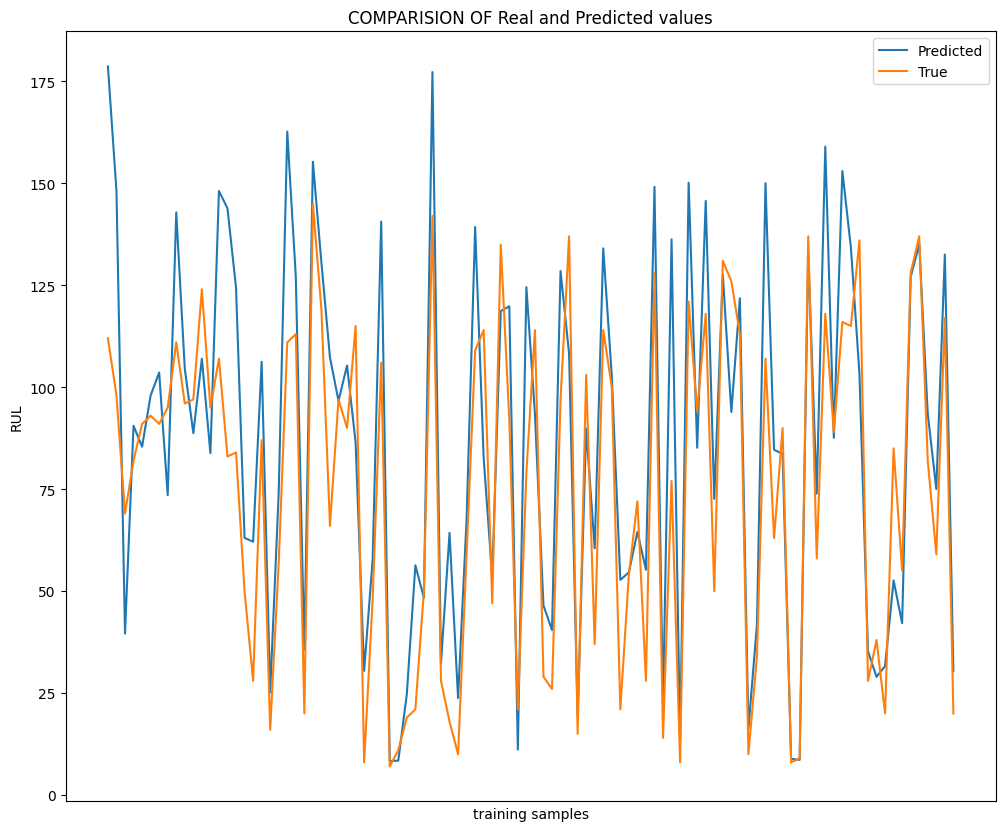

In [ ]:
plot_result(y_true,y_pred)

In [ ]:
underestimated_count = np.sum(y_pred < y_true)
total_predictions = len(y_true)
underestimated_percentage = (underestimated_count / total_predictions) * 100

print(f"Number of underestimated predictions: {underestimated_count}")
print(f"Total test predictions: {total_predictions}")
print(f"Percentage of underestimated predictions: {underestimated_percentage:.2f}%")

Number of underestimated predictions: 30
Total test predictions: 100
Percentage of underestimated predictions: 30.00%


## LSTM funtion calling

In [ ]:
train_df_lstm = pd.concat([unit_number, train_df], axis=1)

In [ ]:
model, history, lstm_test_df, seq_array, label_array, sequence_length, sequence_cols = train_models([train_df_lstm, fd_001_test, RUL.copy()], "LSTM",  base_path + "LSTM")

train_df >>     unit_number  time_in_cycles       T24       T30       T50       P30  \
0            1               1  0.183735  0.406802  0.309757  0.726248   
1            1               2  0.283133  0.453019  0.352633  0.628019   
2            1               3  0.343373  0.369523  0.370527  0.710145   
3            1               4  0.343373  0.256159  0.331195  0.740741   
4            1               5  0.349398  0.257467  0.404625  0.668277   

         Nf        Nc      Ps30       phi       NRf       BPR   htBleed  \
0  0.242424  0.109755  0.369048  0.633262  0.205882  0.363986  0.333333   
1  0.212121  0.100242  0.380952  0.765458  0.279412  0.411312  0.333333   
2  0.272727  0.140043  0.250000  0.795309  0.220588  0.357445  0.166667   
3  0.318182  0.124518  0.166667  0.889126  0.294118  0.166603  0.333333   
4  0.242424  0.149960  0.255952  0.746269  0.235294  0.402078  0.416667   

        W31       W32  RUL  label1  label2  cycle_norm  
0  0.713178  0.724662  191       0

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 100)        │        46,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,051 (300.98 KB)

 Trainable params: 77,051 (300.98 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/60
75/75 - 23s - 304ms/step - loss: 8787.2979 - mae: 74.9581 - r2_keras: -1.6916e+00 - val_loss: 8153.1084 - val_mae: 71.7697 - val_r2_keras: -2.4186e+00
Epoch 2/60
75/75 - 19s - 257ms/step - loss: 8061.5371 - mae: 70.7493 - r2_keras: -1.4696e+00 - val_loss: 7633.2510 - val_mae: 68.7699 - val_r2_keras: -2.1745e+00
Epoch 3/60
75/75 - 24s - 324ms/step - loss: 7551.9468 - mae: 67.8422 - r2_keras: -1.3098e+00 - val_loss: 7142.2725 - val_mae: 65.9537 - val_r2_keras: -1.9457e+00
Epoch 4/60
75/75 - 38s - 501ms/step - loss: 7073.7559 - mae: 65.1229 - r2_keras: -1.1600e+00 - val_loss: 6682.2129 - val_mae: 63.3320 - val_r2_keras: -1.7332e+00
Epoch 5/60
75/75 - 24s - 320ms/step - loss: 6626.2666 - mae: 62.6247 - r2_keras: -1.0247e+00 - val_loss: 6247.5713 - val_mae: 60.8557 - val_r2_keras: -1.5344e+00
Epoch 6/60
75/75 - 21s - 275ms/step - loss: 6205.0747 - mae: 60.2261 - r2_keras: -8.9354e-01 - val_loss: 5842.6602 - val_mae: 58.5574 - val_r2_keras: -1.3514e+00
Epoch 7/60
75/75 - 22s 

dict_keys(['loss', 'mae', 'r2_keras', 'val_loss', 'val_mae', 'val_r2_keras'])
LSTM model saved successfully as /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/LSTM.h5


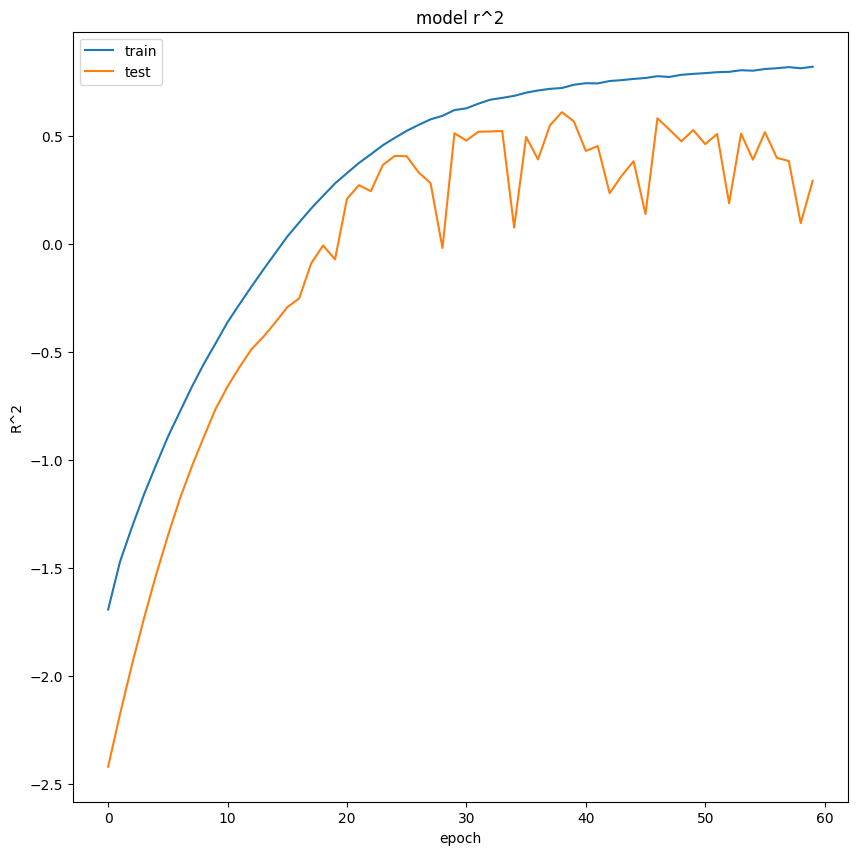

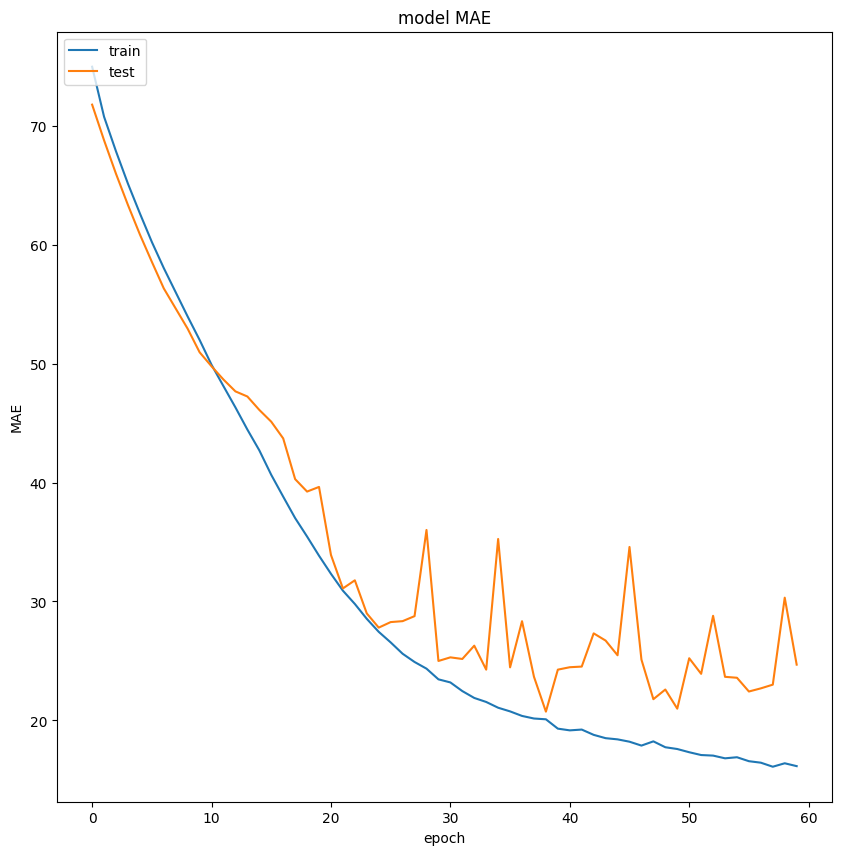

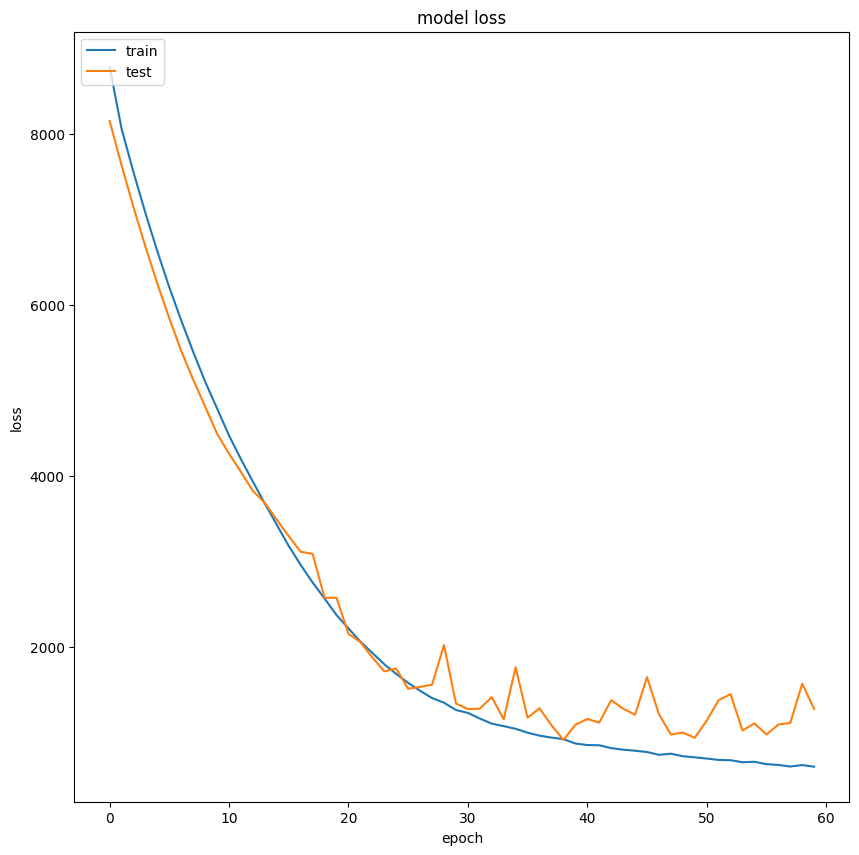

79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - loss: 259.1397 - mae: 9.8544 - r2_keras: 0.8984

MAE: 12.777508735656738

R^2: 0.8289088010787964
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step


In [ ]:
lstm_test_evaluation_graphs(model, history, seq_array, label_array)


In [ ]:
def display_rul_table(y_true, y_pred):
    """
    Displays a table with true and predicted RUL values for each engine.
    """
    # Assuming y_true and y_pred are numpy arrays and correspond to each other
    # Assuming the order corresponds to engine numbers 1 through the total number of engines
    engine_numbers = range(1, len(y_true) + 1)

    results_df = pd.DataFrame({
        'Engine Number': engine_numbers,
        'True RUL': y_true.flatten(),
        'Predicted RUL': y_pred.flatten()
    })

    display(results_df)

# Assuming y_true and y_pred from the LSTM valid evaluation are available
# If not, you might need to run the evaluation cell first (cell_id: vgwAVKilyINs)
# MAE, R2, y_pred_lstm_valid, y_true_lstm_valid = lstm_valid_evaluation(lstm_test_df, model, sequence_length, sequence_cols)
# display_rul_table(y_true_lstm_valid, y_pred_lstm_valid)

In [ ]:
def lstm_valid_evaluation(lstm_test_df, model, sequence_length, sequence_cols):
    # We pick the last sequence for each id in the test data
    print("0 - {} {}".format(lstm_test_df, lstm_test_df.shape))

    # Modified to include all engines and pad sequences
    seq_array_test_last = []
    for id in lstm_test_df['unit_number'].unique():
        engine_df = lstm_test_df[lstm_test_df['unit_number']==id][sequence_cols].values
        num_elements = engine_df.shape[0]
        if num_elements < sequence_length:
            padding = np.zeros((sequence_length - num_elements, engine_df.shape[1]))
            engine_df = np.concatenate((padding, engine_df), axis=0)
        seq_array_test_last.append(engine_df[-sequence_length:])


    print("1 - {} {}".format(lstm_test_df, lstm_test_df.shape))

    seq_array_test_last = np.asarray(seq_array_test_last).astype(np.float32)

    print("2 - {} {}".format(lstm_test_df, lstm_test_df.shape))

    # Similarly, we pick the labels (the last RUL for each engine)
    label_array_test_last = lstm_test_df.groupby('unit_number')['RUL'].nth(-1).values
    label_array_test_last = label_array_test_last.reshape(label_array_test_last.shape[0],1).astype(np.float32)


    estimator = model

    # test metrics
    scores_test = estimator.evaluate(seq_array_test_last, label_array_test_last, verbose=2)
    print('\nMAE: {}'.format(scores_test[1]))
    print('\nR^2: {}'.format(scores_test[2]))

    y_pred_test = estimator.predict(seq_array_test_last)
    y_true_test = label_array_test_last

    test_set = pd.DataFrame(y_pred_test)
    print(test_set.head())

    # Plot in blue color the predicted data and in green color the
    # actual data to verify visually the accuracy of the model.
    fig_verify = plt.figure(figsize=(10, 5))
    plt.plot(y_pred_test)
    plt.plot(y_true_test, color="orange")
    plt.title('prediction')
    plt.ylabel('value')
    plt.xlabel('row')
    plt.legend(['predicted', 'actual data'], loc='upper left')
    plt.show()
    # fig_verify.savefig("model_regression_verify.png")
    return scores_test[1], scores_test[2], y_pred_test, y_true_test

MAE, R2, y_pred, y_true = lstm_valid_evaluation(lstm_test_df, model, sequence_length, sequence_cols)
display_rul_table(y_true, y_pred)
# mae, rmse, r2
rmse_lstm = np.sqrt(mean_squared_error(y_true, y_pred))
LSTM_individual_scorelst = [round(MAE, 2), round(rmse_lstm, 2), round(R2, 2) * 100]

print(f"\nEvaluation Parameters:")
print(f"MAE: {MAE:.2f}")
print(f"R-squared: {R2:.2f}")
print(f"RMSE: {rmse_lstm:.2f}")

NameError: name 'lstm_test_df' is not defined

In [ ]:
underestimated_count = np.sum(y_pred < y_true)
total_predictions = len(y_true)
underestimated_percentage = (underestimated_count / total_predictions) * 100

print(f"Number of underestimated predictions: {underestimated_count}")
print(f"Total test predictions: {total_predictions}")
print(f"Percentage of underestimated predictions: {underestimated_percentage:.2f}%")

Number of underestimated predictions: 47
Total test predictions: 100
Percentage of underestimated predictions: 47.00%


0 -        unit_number  time_in_cycles       T24       T30       T50       P30  \
0                1               1  0.545181  0.310661  0.269413  0.652174   
1                1               2  0.150602  0.379551  0.222316  0.805153   
2                1               3  0.376506  0.346632  0.322248  0.685990   
3                1               4  0.370482  0.285154  0.408001  0.679549   
4                1               5  0.391566  0.352082  0.332039  0.694042   
...            ...             ...       ...       ...       ...       ...   
13091          100             194  0.611446  0.619359  0.566172  0.573269   
13092          100             195  0.605422  0.537388  0.671843  0.542673   
13093          100             196  0.671687  0.482014  0.414754  0.513688   
13094          100             197  0.617470  0.522128  0.626435  0.566828   
13095          100             198  0.524096  0.666667  0.721472  0.423510   

             Nf        Nc      Ps30       phi       NRf    

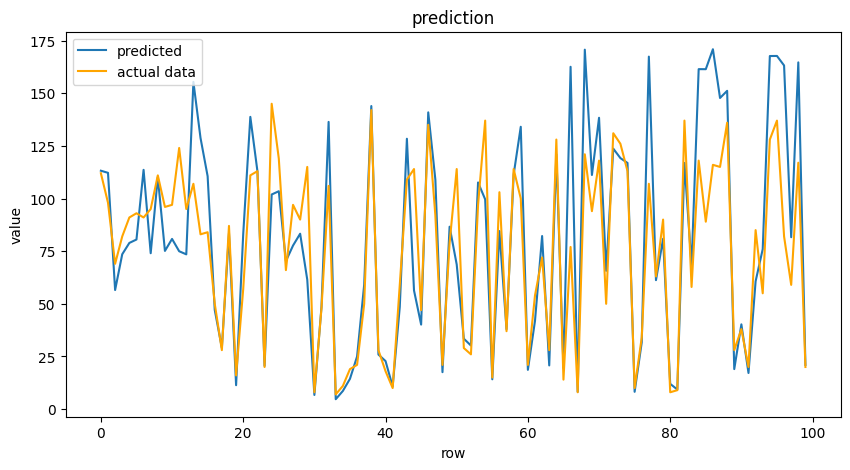

,Engine Number,True RUL,Predicted RUL
0,1,112.0,113.200630
1,2,98.0,112.203194
2,3,69.0,56.549938
3,4,82.0,73.532471
4,5,91.0,78.909401
...,...,...,...
95,96,137.0,167.694122
96,97,82.0,163.178146
97,98,59.0,81.618111
98,99,117.0,164.643906


In [ ]:
MAE, R2, y_pred, y_true = lstm_valid_evaluation(lstm_test_df, model, sequence_length, sequence_cols)
display_rul_table(y_true, y_pred)
# mae, rmse, r2
LSTM_individual_scorelst = [round(MAE,2), 0, round(R2,2)*100]


Let’s try to improve the algorithm for predicting the results, for this we will train the model each time again for each individual prediction, discarding in the training array the values ​​on the timeline (time_in_cycles) are smaller than the last value in the fd_001_test array, that is, lower than the value for which RUL should be predicted (remaining useful life)

In [ ]:
model


<Sequential name=sequential_1, built=True>

In [ ]:
# to discard values in the training array, use the factor parameter in
# prepare_train_data functions, in test_data are samples prepared for recognition, in the first column of which
# - value of time in cycles for which RUL is predicted
def single_train(test_data,train_data,algorithm):
    y_single_pred = []
    for sample in tqdm(test_data):
        time.sleep(0.01)
        single_train_df = prepare_train_data(train_data, factor = sample[0])
        single_train_df.drop(columns = ['unit_number','setting_1','setting_2','P15','NRc'],inplace = True)
        model = train_models(single_train_df,algorithm)
        y_p = model.predict(sample.reshape(1,-1))[0]
        y_single_pred.append(y_p)
    y_single_pred = np.array(y_single_pred)
    return y_single_pred

In [ ]:
def predict_rul_for_engine(engine_number, filepath='lstm_model'):
    """
    Loads the LSTM model and predicts the RUL for a specific engine number.
    """
    # Load the model and data
    model, history, model_data = load_lstm_model(filepath)
    lstm_test_df = model_data['lstm_test_df']
    sequence_length = model_data['sequence_length']
    sequence_cols = model_data['sequence_cols']

    # Filter data for the specific engine
    engine_df = lstm_test_df[lstm_test_df['unit_number'] == engine_number]

    # if len(engine_df) < sequence_length:
    #     print(f"Engine {engine_number} does not have enough cycles ({len(engine_df)}) for sequence length ({sequence_length}). Cannot predict RUL.")
    #     return None

    # Get the last sequence for the engine
    seq_array_engine = [engine_df[sequence_cols].values[-sequence_length:]]
    seq_array_engine = np.asarray(seq_array_engine).astype(np.float32)

    # Predict RUL
    predicted_rul = model.predict(seq_array_engine)

    return predicted_rul[0][0]

In [ ]:
# Example usage: Predict RUL for engine number 1
engine_number_to_predict = 3
predicted_rul = predict_rul_for_engine(engine_number_to_predict, base_path + "LSTM")

if predicted_rul is not None:
    print(f"Predicted RUL for engine {engine_number_to_predict}: {predicted_rul}")

LSTM model loaded successfully from /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/LSTM.h5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
Predicted RUL for engine 3: 51.638153076171875


In [ ]:
!pip install fastapi uvicorn nest_asyncio

In [ ]:
from fastapi import FastAPI
import uvicorn
import nest_asyncio
import pandas as pd
import numpy as np
import tensorflow as tf
import pickle
from tensorflow.keras.models import load_model

In [ ]:
# Load the LSTM model
# Make sure the load_lstm_model function is defined and accessible
# Assuming the model is saved at base_path + "LSTM"
try:
    model, history, model_data = load_lstm_model(base_model_path + "LSTM")
    lstm_test_df = model_data['lstm_test_df']
    sequence_length = model_data['sequence_length']
    sequence_cols = model_data['sequence_cols']
    print("LSTM model loaded successfully.")
except Exception as e:
    print(f"Error loading LSTM model: {e}")
    model = None
    lstm_test_df = None
    sequence_length = None
    sequence_cols = None

LSTM model loaded successfully from /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/Models/LSTM/LSTM.h5
LSTM model loaded successfully.


In [ ]:
app = FastAPI()

@app.get("/predict_rul/{engine_number}")
def predict_rul_for_engine_api(engine_number: int):
    """
    Predicts the RUL for a specific engine number using the loaded LSTM model.
    """
    if model is None:
        return {"error": "LSTM model not loaded."}

    try:
        # Filter data for the specific engine
        engine_df = lstm_test_df[lstm_test_df['unit_number'] == engine_number]

        if engine_df.empty:
            return {"error": f"Engine number {engine_number} not found in test data."}

        # Pad sequence if shorter than sequence_length
        engine_sequence = engine_df[sequence_cols].values
        num_elements = engine_sequence.shape[0]
        if num_elements < sequence_length:
            padding = np.zeros((sequence_length - num_elements, engine_sequence.shape[1]))
            engine_sequence = np.concatenate((padding, engine_sequence), axis=0)

        # Get the last sequence for the engine
        seq_array_engine = [engine_sequence[-sequence_length:]]
        seq_array_engine = np.asarray(seq_array_engine).astype(np.float32)


        # Predict RUL
        predicted_rul = model.predict(seq_array_engine)

        return {"engine_number": engine_number, "predicted_rul": float(predicted_rul[0][0])}

    except Exception as e:
        return {"error": f"An error occurred during prediction: {e}"}

@app.get("/engines_with_low_rul/{threshold}")
def get_engines_with_low_rul(threshold: float = 50.0):
    """
    Returns a list of engine numbers with predicted RUL less than a specified threshold.
    """
    if model is None:
        return {"error": "LSTM model not loaded."}

    try:
        low_rul_engines = []
        # Assuming lstm_test_df contains data for all engines
        for engine_number in lstm_test_df['unit_number'].unique():
             # Filter data for the specific engine
            engine_df = lstm_test_df[lstm_test_df['unit_number'] == engine_number]

            if engine_df.empty:
                continue

            # Pad sequence if shorter than sequence_length
            engine_sequence = engine_df[sequence_cols].values
            num_elements = engine_sequence.shape[0]
            if num_elements < sequence_length:
                padding = np.zeros((sequence_length - num_elements, engine_sequence.shape[1]))
                engine_sequence = np.concatenate((padding, engine_sequence), axis=0)

            # Get the last sequence for the engine
            seq_array_engine = [engine_sequence[-sequence_length:]]
            seq_array_engine = np.asarray(seq_array_engine).astype(np.float32)

            predicted_rul = model.predict(seq_array_engine)

            if predicted_rul[0][0] < threshold:
                low_rul_engines.append({"engine_number": int(engine_number), "predicted_rul": float(predicted_rul[0][0])})

        return {"low_rul_engines": low_rul_engines}

    except Exception as e:
        return {"error": f"An error occurred while finding low RUL engines: {e}"}

from pydantic import BaseModel, Field
from typing import List

# Define the expected data structure for the new engine prediction API
class EngineData(BaseModel):
    data: List[List[float]] = Field(
        ...,
        description=(
            f"A list of lists representing the time series data for the engine. "
            f"Each inner list represents a time step and must contain {len(sequence_cols)} "
            f"float values corresponding to the sequence columns: {sequence_cols}. "
            f"The outer list represents the sequence of time steps. "
            f"The number of time steps can be less than, equal to, or greater than the sequence length ({sequence_length}). "
            f"If less, it will be padded. If greater, only the last {sequence_length} time steps will be used."
        )
    )

@app.post("/predict_new_engine_rul/")
def predict_new_engine_rul_api(engine_data: EngineData):
    """
    Predicts the RUL for a new engine based on a sequence of data.
    The input data should be a list of time steps, where each time step is a list of feature values
    in the order defined by `sequence_cols`.
    """
    if model is None:
        return {"error": "LSTM model not loaded."}

    try:
        # Convert the input data to a numpy array
        new_engine_sequence = np.asarray(engine_data.data).astype(np.float32)

        # Ensure the input sequence has the correct number of features
        if new_engine_sequence.shape[1] != len(sequence_cols):
             return {"error": f"Input data must have {len(sequence_cols)} features per time step, but got {new_engine_sequence.shape[1]}."}

        # Handle sequence length: pad if shorter, truncate if longer
        num_elements = new_engine_sequence.shape[0]
        if num_elements < sequence_length:
            # Pad with zeros at the beginning
            padding = np.zeros((sequence_length - num_elements, new_engine_sequence.shape[1]))
            processed_sequence = np.concatenate((padding, new_engine_sequence), axis=0)
        elif num_elements > sequence_length:
             # Take the last 'sequence_length' elements
             processed_sequence = new_engine_sequence[-sequence_length:]
        else:
             # Sequence length is exactly 'sequence_length'
             processed_sequence = new_engine_sequence


        # Reshape the sequence for prediction (add batch dimension)
        seq_array_new_engine = np.asarray([processed_sequence]).astype(np.float32)

        # Predict RUL
        predicted_rul = model.predict(seq_array_new_engine)

        return {"predicted_rul": float(predicted_rul[0][0])}

    except Exception as e:
        return {"error": f"An error occurred during prediction for the new engine: {e}"}

## Running the FastAPI Application

To run the FastAPI application in Colab, you can use `uvicorn` and `nest_asyncio`. `nest_asyncio` is needed to run the asynchronous application in the Colab environment.

First, make sure you have executed the cell above (cell id: `c0ed6fca`) to define the `app`.

Then, execute the following code cell to run the application:

In [ ]:
import nest_asyncio
nest_asyncio.apply()

import uvicorn

# Run the FastAPI application
# Use run_forever=False to allow other cells to be executed after this one
uvicorn.run(app, host="0.0.0.0", port=8000, run_forever=False)

Once the application is running, you can access the API endpoints. You might need to use a tool like `ngrok` to expose your Colab environment's port to the internet if you want to access it from outside Colab. However, for testing within Colab, you can often use `localhost` or the internal IP address.

## Example cURL Commands

Here are example `curl` commands for each of the API endpoints, assuming the application is running on `localhost` at port `8000`.

### Predict RUL for a specific engine

This command predicts the RUL for engine number 3. Replace `3` with the desired engine number.

In [ ]:
# curl "http://localhost:8000/engines_with_low_rul/50.0"

In [ ]:
# curl -X POST "http://localhost:8000/predict_new_engine_rul/" \
# -H "Content-Type: application/json" \
# -d '{"data": [[0.0, 1.0, 0.545181, 0.310661, 0.269413, 0.652174, 0.212121, 0.127614, 0.208333, 0.646055, 0.220588, 0.308965, 0.333333, 0.558140, 0.661834, 0.0], [0.0, 2.0, 0.150602, 0.379551, 0.222316, 0.805153, 0.166667, 0.146684, 0.386905, 0.739872, 0.264706, 0.213159, 0.416667, 0.682171, 0.686827, 0.00277], [0.0, 3.0, 0.376506, 0.346632, 0.322248, 0.685990, 0.227273, 0.158081, 0.386905, 0.699360, 0.220588, 0.458638, 0.416667, 0.728682, 0.721348, 0.00554]]}'

In [ ]:
# Use an official Python runtime as a parent image
FROM python:3.9-slim

# Set the working directory in the container
WORKDIR /app

# Copy the requirements file into the container
COPY requirements.txt .

# Install any needed packages specified in requirements.txt
RUN pip install --no-cache-dir -r requirements.txt

# Copy the FastAPI application code into the container
# Assuming your FastAPI application code is in a file named main.py
COPY main.py .

# Copy the trained model file into the container
# Make sure the path here matches where your model is saved
COPY /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/Models/LSTM/LSTM.h5 ./models/LSTM.h5
COPY /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/Models/LSTM/LSTM_history.pkl ./models/LSTM_history.pkl
COPY /content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMAPS/Models/LSTM/LSTM_data.pkl ./models/LSTM_data.pkl

# Expose the port the app runs on
EXPOSE 8000

# Run the FastAPI application
# Assumes your FastAPI app instance is named 'app' and your application file is 'main.py'
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]

In [ ]:
fastapi
uvicorn
nest_asyncio
pandas
numpy
tensorflow
scikit-learn
torch
torch-geometric

NameError: name 'fastapi' is not defined